# Census Income: End-to-End Machine Learning Assignment

In this project, you will use census attributes to predict whether a person belongs to the `>50K` or `<=50K` annual-income group. Imagine a nonprofit such as CharityML is using income estimates to guide donor outreach: identifying likely donors can help prioritize contact, while incorrectly targeting people can waste limited outreach time. Treat this as a teaching scenario, not evidence that income determines whether someone will donate.

Use `census.csv` as the labeled dataset and `income` as the target. The records are based on the 1994 U.S. Census income data; the provided version uses fields such as `education_level` and omits some fields found in the original dataset. `test_census.csv` has no income labels, so reserve it for optional predictions after selecting and evaluating your model. Do not use it to calculate scores.

Complete each TODO in order. Explain important choices, inspect the data rather than assuming what it contains, and prevent data leakage by fitting learned preprocessing steps on training data only. Save the complete fitted preprocessing-and-model pipeline, not just the classifier.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Explore the Data
Load `census.csv` and inspect its rows, shape, data types, category values, missing or special-value markers, and numeric distributions. The `income` target has two groups, `>50K` and `<=50K`; quantify their counts and proportions, then visualize the imbalance. Establish a simple majority-class baseline so later model scores have a meaningful point of comparison. Note that the dataset includes income, education, work, household, and demographic attributes.

In [ ]:
# TODO: Implement task 1
census_df=pd.read_csv('census.csv')
census_df.head(500)

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,<=50K
2,38,Private,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53,Private,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28,Private,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,31,Self-emp-inc,Bachelors,13.0,Never-married,Farming-fishing,Not-in-family,White,Female,0.0,0.0,45.0,United-States,<=50K
496,44,Private,Some-college,10.0,Married-civ-spouse,Transport-moving,Husband,White,Male,0.0,0.0,40.0,United-States,<=50K
497,29,Private,Doctorate,16.0,Never-married,Prof-specialty,Own-child,White,Male,0.0,0.0,40.0,United-States,<=50K
498,30,Private,Some-college,10.0,Never-married,Handlers-cleaners,Unmarried,White,Female,0.0,0.0,40.0,United-States,<=50K


In [1]:
from ml_utils import describe_with_whisker,validate_incoming_data,optimize_memory

In [ ]:
census_df.describe(include='all')

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,45222.000000,45222,45222,45222.000000,45222,45222,45222,45222,45222,45222.000000,45222.000000,45222.000000,45222,45222
unique,NaN,7,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,HS-grad,NaN,Married-civ-spouse,Craft-repair,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,33307,14783,NaN,21055,6020,18666,38903,30527,NaN,NaN,NaN,41292,34014
mean,38.547941,NaN,NaN,10.118460,NaN,NaN,NaN,NaN,NaN,1101.430344,88.595418,40.938017,NaN,NaN
std,13.217870,NaN,NaN,2.552881,NaN,NaN,NaN,NaN,NaN,7506.430084,404.956092,12.007508,NaN,NaN
min,17.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,47.000000,NaN,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [ ]:
census_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              45222 non-null  int64  
 1   workclass        45222 non-null  object 
 2   education_level  45222 non-null  object 
 3   education-num    45222 non-null  float64
 4   marital-status   45222 non-null  object 
 5   occupation       45222 non-null  object 
 6   relationship     45222 non-null  object 
 7   race             45222 non-null  object 
 8   sex              45222 non-null  object 
 9   capital-gain     45222 non-null  float64
 10  capital-loss     45222 non-null  float64
 11  hours-per-week   45222 non-null  float64
 12  native-country   45222 non-null  object 
 13  income           45222 non-null  object 
dtypes: float64(4), int64(1), object(9)
memory usage: 4.8+ MB


In [ ]:
census_df.isnull().sum()

,0
age,0
workclass,0
education_level,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0
capital-gain,0


In [ ]:
census_df.duplicated(keep=False).sum()

np.int64(9291)

In [ ]:
duplicates_to_view = census_df[census_df.duplicated(keep=False)]
display(duplicates_to_view.sort_values(by=list(census_df.columns)).head(1000))

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
32051,17,Private,10th,6.0,Never-married,Handlers-cleaners,Own-child,White,Male,0.0,0.0,15.0,United-States,<=50K
42555,17,Private,10th,6.0,Never-married,Handlers-cleaners,Own-child,White,Male,0.0,0.0,15.0,United-States,<=50K
16398,17,Private,10th,6.0,Never-married,Handlers-cleaners,Own-child,White,Male,0.0,0.0,20.0,United-States,<=50K
22259,17,Private,10th,6.0,Never-married,Handlers-cleaners,Own-child,White,Male,0.0,0.0,20.0,United-States,<=50K
22990,17,Private,10th,6.0,Never-married,Handlers-cleaners,Own-child,White,Male,0.0,0.0,20.0,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12887,20,Private,Some-college,10.0,Never-married,Adm-clerical,Own-child,White,Female,0.0,0.0,35.0,United-States,<=50K
19412,20,Private,Some-college,10.0,Never-married,Adm-clerical,Own-child,White,Female,0.0,0.0,35.0,United-States,<=50K
23314,20,Private,Some-college,10.0,Never-married,Adm-clerical,Own-child,White,Female,0.0,0.0,35.0,United-States,<=50K
35735,20,Private,Some-college,10.0,Never-married,Adm-clerical,Own-child,White,Female,0.0,0.0,35.0,United-States,<=50K


### Observation on Duplicated Rows

After checking the duplicated rows, we can see that they represent very common groups in the real world (for example, 18-year-old young people working the same hours in similar jobs).

Because our dataset does not have a "Unique ID" column (like a personal ID or social security number), we believe these are different real people, not data entry mistakes. This is known as **Natural Duplicates**.

**Decision:** We will **NOT** drop these duplicates. Keeping them helps the model understand the real society and prevents bias.

In [ ]:
census_df.dtypes

,0
age,int64
workclass,object
education_level,object
education-num,float64
marital-status,object
occupation,object
relationship,object
race,object
sex,object
capital-gain,float64


In [ ]:
numerical_col=['age','education-num','capital-gain','capital-loss','hours-per-week']
cat_col=[col for col in census_df.columns if col not in numerical_col]


In [ ]:
for col in cat_col:
  print(f"--- {col} ---")
  print(census_df[col].unique())
  print("\n")

--- workclass ---
[' State-gov' ' Self-emp-not-inc' ' Private' ' Federal-gov' ' Local-gov'
 ' Self-emp-inc' ' Without-pay']


--- education_level ---
[' Bachelors' ' HS-grad' ' 11th' ' Masters' ' 9th' ' Some-college'
 ' Assoc-acdm' ' 7th-8th' ' Doctorate' ' Assoc-voc' ' Prof-school'
 ' 5th-6th' ' 10th' ' Preschool' ' 12th' ' 1st-4th']


--- marital-status ---
[' Never-married' ' Married-civ-spouse' ' Divorced'
 ' Married-spouse-absent' ' Separated' ' Married-AF-spouse' ' Widowed']


--- occupation ---
[' Adm-clerical' ' Exec-managerial' ' Handlers-cleaners' ' Prof-specialty'
 ' Other-service' ' Sales' ' Transport-moving' ' Farming-fishing'
 ' Machine-op-inspct' ' Tech-support' ' Craft-repair' ' Protective-serv'
 ' Armed-Forces' ' Priv-house-serv']


--- relationship ---
[' Not-in-family' ' Husband' ' Wife' ' Own-child' ' Unmarried'
 ' Other-relative']


--- race ---
[' White' ' Black' ' Asian-Pac-Islander' ' Amer-Indian-Eskimo' ' Other']


--- sex ---
[' Male' ' Female']


--- native-c

In [ ]:
value_c = census_df[cat_col].nunique()
display(value_c)

,0
workclass,7
education_level,16
marital-status,7
occupation,14
relationship,6
race,5
sex,2
native-country,41
income,2


In [ ]:
for col in census_df[cat_col]:
    display(census_df[col].value_counts())


,count
workclass,
Private,33307
Self-emp-not-inc,3796
Local-gov,3100
State-gov,1946
Self-emp-inc,1646
Federal-gov,1406
Without-pay,21


,count
education_level,
HS-grad,14783
Some-college,9899
Bachelors,7570
Masters,2514
Assoc-voc,1959
11th,1619
Assoc-acdm,1507
10th,1223
7th-8th,823


,count
marital-status,
Married-civ-spouse,21055
Never-married,14598
Divorced,6297
Separated,1411
Widowed,1277
Married-spouse-absent,552
Married-AF-spouse,32


,count
occupation,
Craft-repair,6020
Prof-specialty,6008
Exec-managerial,5984
Adm-clerical,5540
Sales,5408
Other-service,4808
Machine-op-inspct,2970
Transport-moving,2316
Handlers-cleaners,2046


,count
relationship,
Husband,18666
Not-in-family,11702
Own-child,6626
Unmarried,4788
Wife,2091
Other-relative,1349


,count
race,
White,38903
Black,4228
Asian-Pac-Islander,1303
Amer-Indian-Eskimo,435
Other,353


,count
sex,
Male,30527
Female,14695


,count
native-country,
United-States,41292
Mexico,903
Philippines,283
Germany,193
Puerto-Rico,175
Canada,163
El-Salvador,147
India,147
Cuba,133


,count
income,
<=50K,34014
>50K,11208


In [ ]:
for col in cat_col:
  spaces_count = census_df[col].astype(str).str.contains(r'^\s|\s$').sum()
  print(f"Rows with leading/trailing spaces in {col}: {spaces_count}")
  q_count = census_df[col].astype(str).str.contains(r'\?').sum()
  print(f"Rows with '?' in {col}: {q_count}")

Rows with leading/trailing spaces in workclass: 45222
Rows with '?' in workclass: 0
Rows with leading/trailing spaces in education_level: 45222
Rows with '?' in education_level: 0
Rows with leading/trailing spaces in marital-status: 45222
Rows with '?' in marital-status: 0
Rows with leading/trailing spaces in occupation: 45222
Rows with '?' in occupation: 0
Rows with leading/trailing spaces in relationship: 45222
Rows with '?' in relationship: 0
Rows with leading/trailing spaces in race: 45222
Rows with '?' in race: 0
Rows with leading/trailing spaces in sex: 45222
Rows with '?' in sex: 0
Rows with leading/trailing spaces in native-country: 45222
Rows with '?' in native-country: 0
Rows with leading/trailing spaces in income: 0
Rows with '?' in income: 0


In [ ]:
for col in cat_col:
    census_df[col] = census_df[col].astype(str).str.strip()

In [ ]:
spaces_count

np.int64(0)

## Fix data types and optimize memory

In [ ]:
from ml_utils import optimize_memory
optimize_memory(census_df)

Memory decreased from 24.22 MB to 1.13 MB (95.3% reduction).


,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,<=50K
2,38,Private,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53,Private,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28,Private,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,33,Private,Bachelors,13.0,Never-married,Prof-specialty,Own-child,White,Male,0.0,0.0,40.0,United-States,<=50K
45218,39,Private,Bachelors,13.0,Divorced,Prof-specialty,Not-in-family,White,Female,0.0,0.0,36.0,United-States,<=50K
45219,38,Private,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,0.0,0.0,50.0,United-States,<=50K
45220,44,Private,Bachelors,13.0,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455.0,0.0,40.0,United-States,<=50K


In [ ]:
from ml_utils import describe_with_whisker
describe_with_whisker(census_df)

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,45222.000000,45222,45222,45222.000000,45222,45222,45222,45222,45222,45222.000000,45222.000000,45222.000000,45222,45222
unique,NaN,7,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,HS-grad,NaN,Married-civ-spouse,Craft-repair,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,33307,14783,NaN,21055,6020,18666,38903,30527,NaN,NaN,NaN,41292,34014
mean,38.547941,NaN,NaN,10.118460,NaN,NaN,NaN,NaN,NaN,1101.430298,88.595421,40.938019,NaN,NaN
std,13.217870,NaN,NaN,2.552767,NaN,NaN,NaN,NaN,NaN,7506.940918,404.898315,12.009028,NaN,NaN
min,17.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,47.000000,NaN,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


# Univariate Analysis

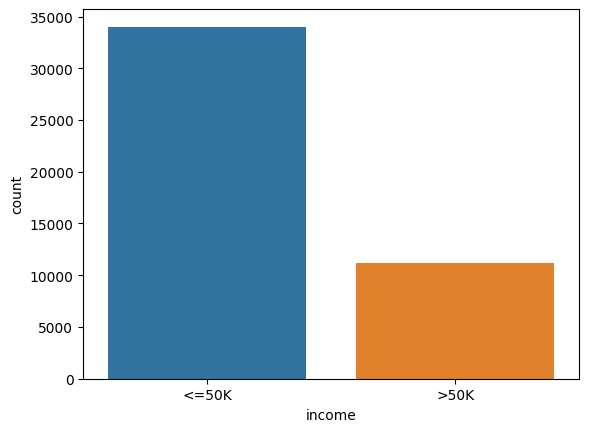

In [ ]:
sns.countplot(data=census_df, x='income',hue='income')
plt.show()

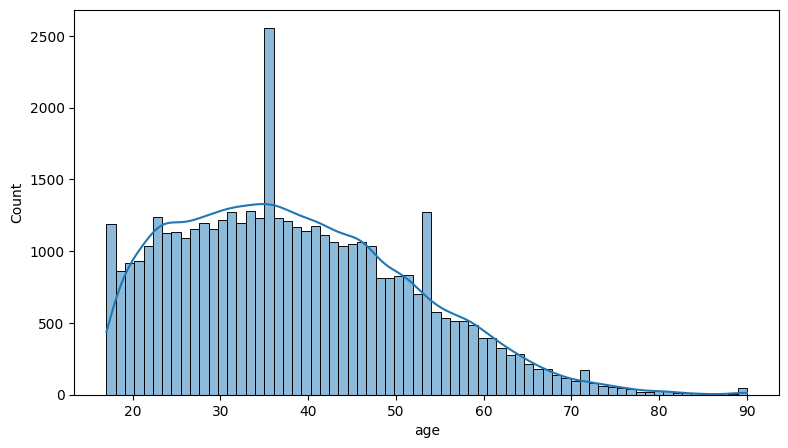

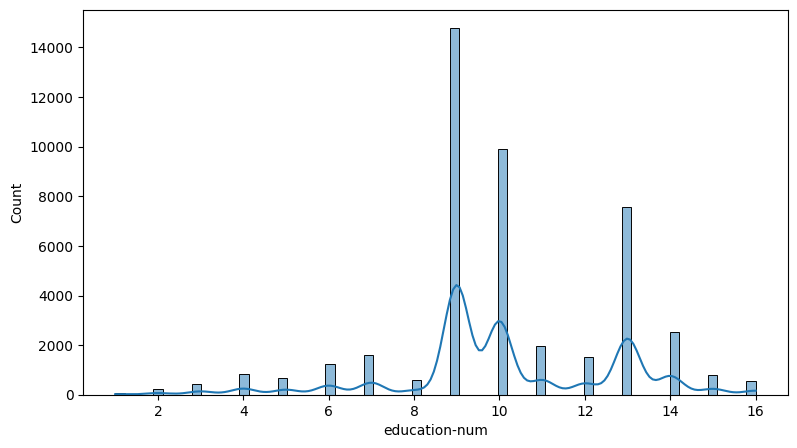

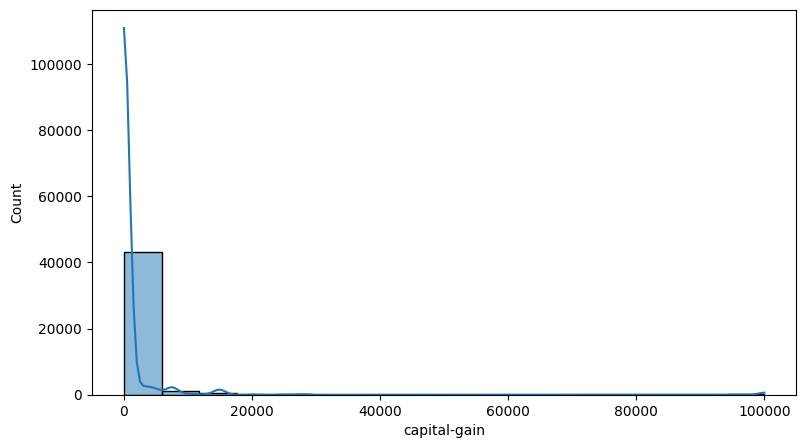

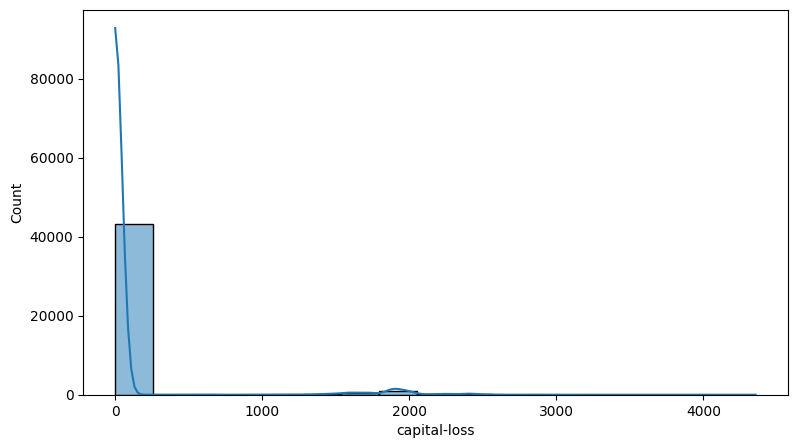

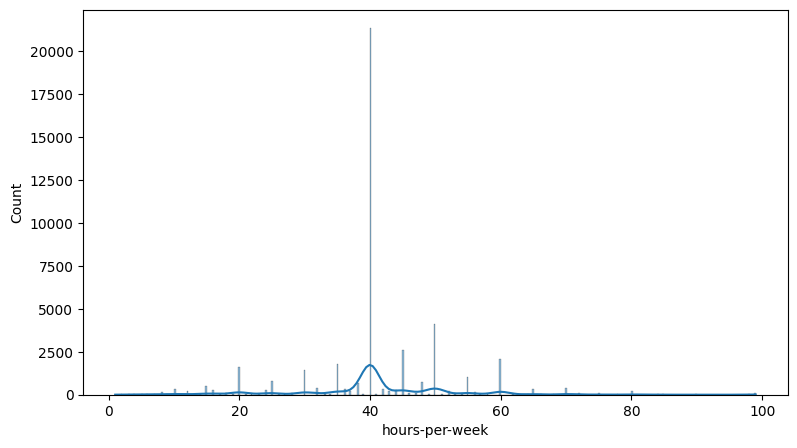

In [ ]:
for cols in numerical_col:
  plt.figure(figsize=(20,5))
  plt.subplot(1,2,1)
  sns.histplot(census_df[cols], kde=True)

### 💡 Univariate Insights:

- **Target Variable (Income):** The dataset suffers from a clear **class imbalance**. The majority of the people belong to the `<=50K` class.
  - *Future Problem:* This imbalance will make the machine learning model biased toward the majority class. The model will struggle to correctly predict the minority class (`>50K`), and using simple 'Accuracy' to evaluate it will be misleading.
- **Capital Gain & Loss:** Both show an extreme right-skewed distribution, as almost all values are concentrated at zero.
- **Hours-per-week:** The distribution is slightly right-skewed, with a massive concentration exactly at 40 hours (the standard full-time work week).
- **Education Number:** It has a multimodal distribution (not a normal distribution). It shows distinct peaks at specific numbers like 9 (HS-grad) and 13 (Bachelors), which makes sense since these numbers represent specific education degrees.
- **Age:** The distribution is slightly right-skewed, with most people falling between 20 and 40 years old.

##Multivariate Analysis

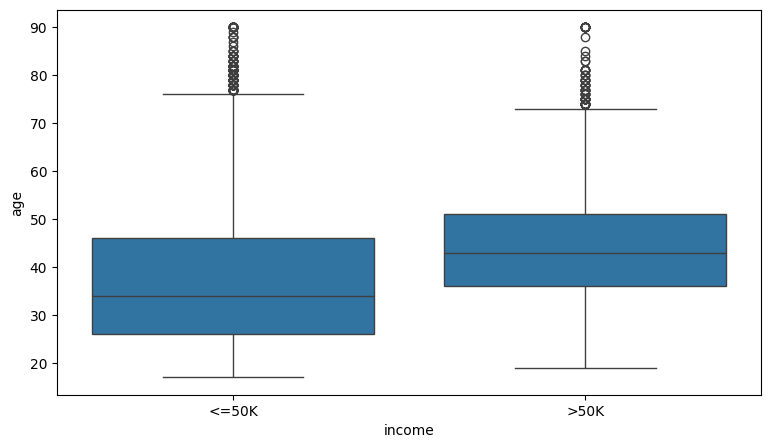

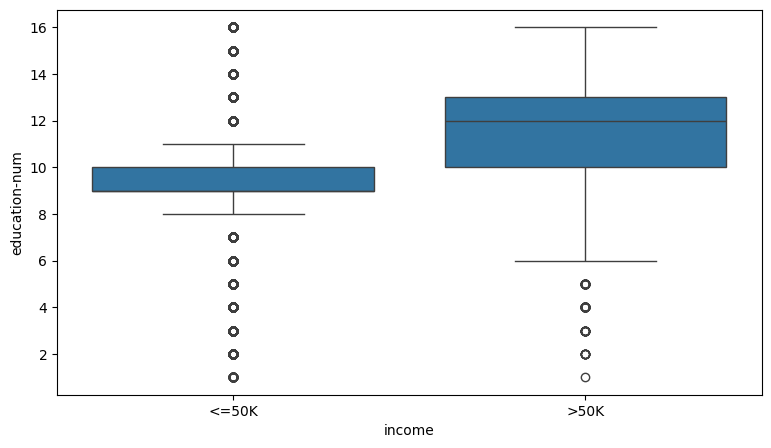

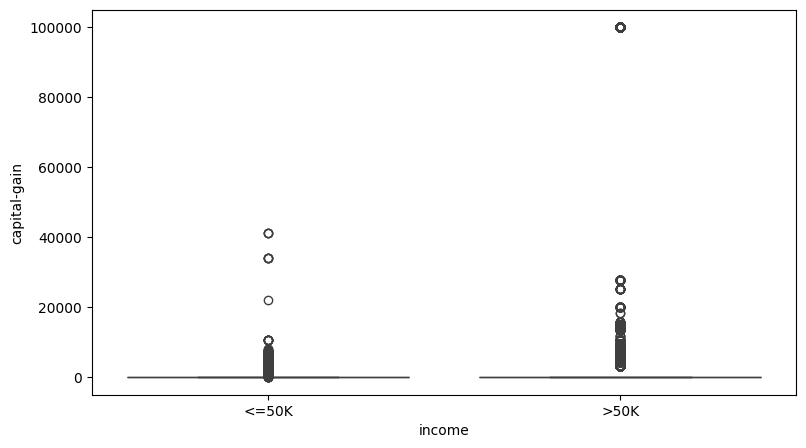

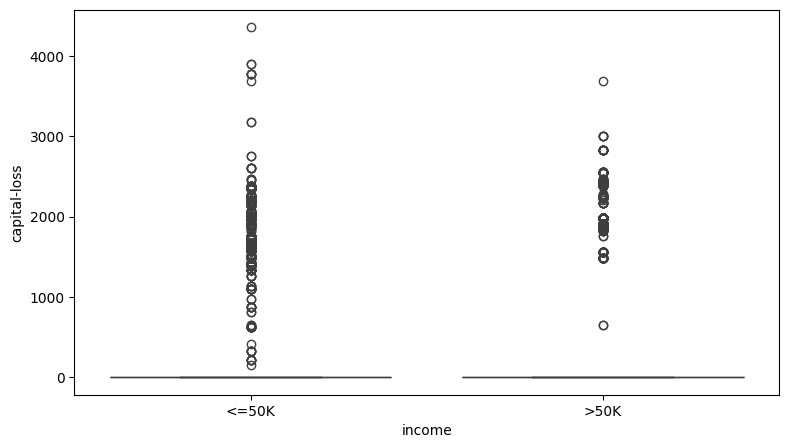

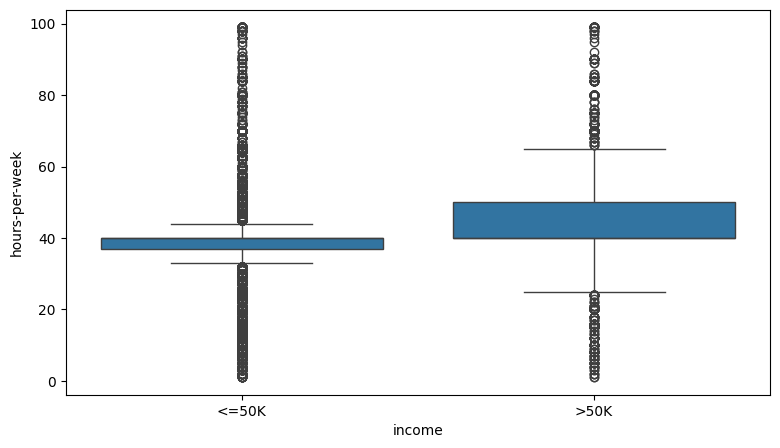

In [ ]:
for i in range(0, len(numerical_col)):
  fig = plt.figure(figsize=(20, 5))
  plt.subplot(1, 2, 1)
  sns.boxplot(data=census_df, x='income', y=numerical_col[i])

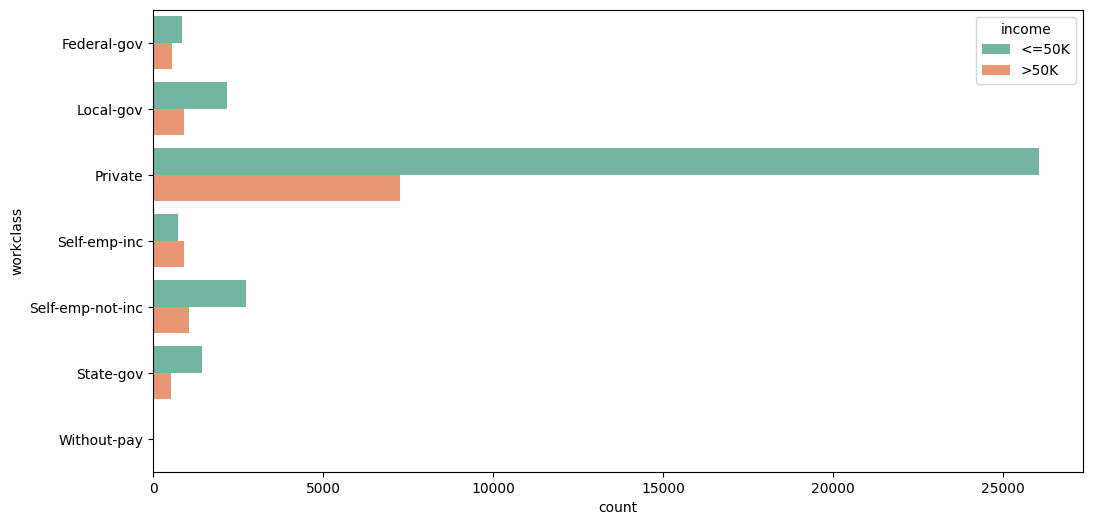

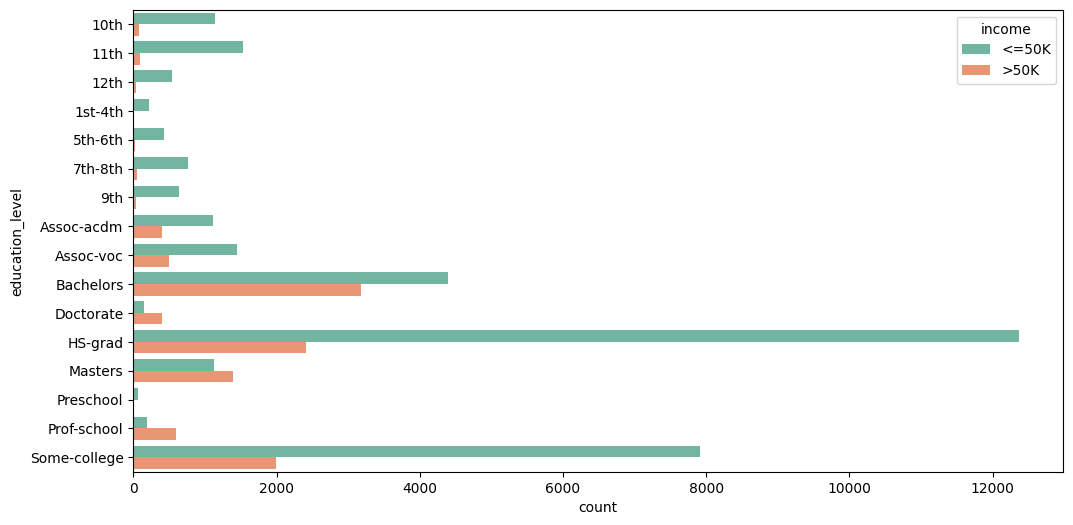

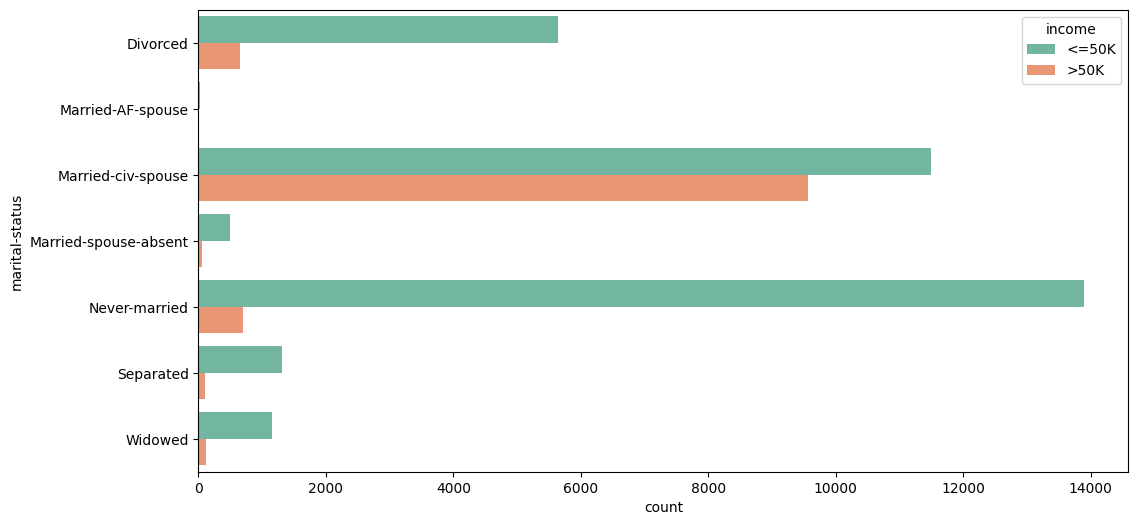

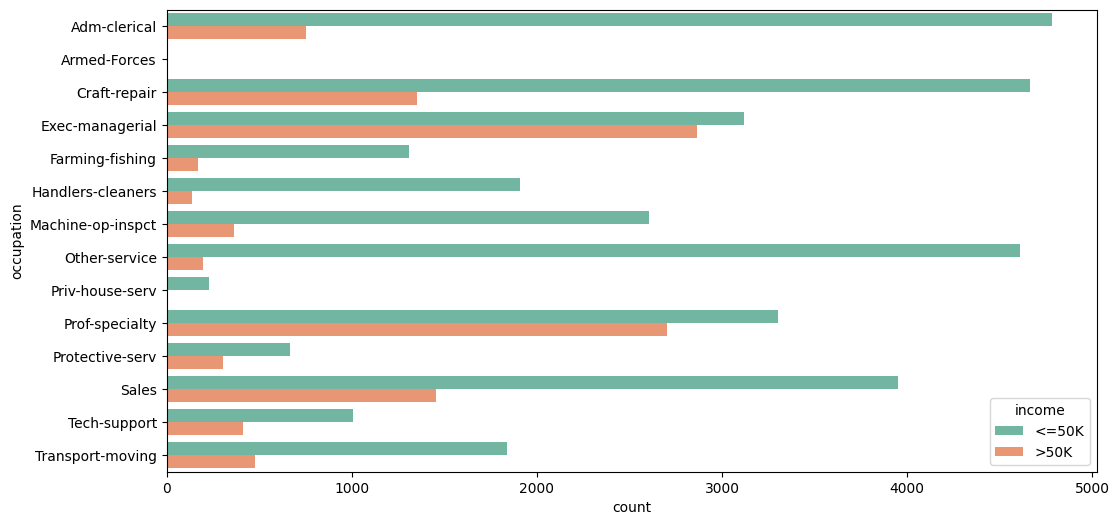

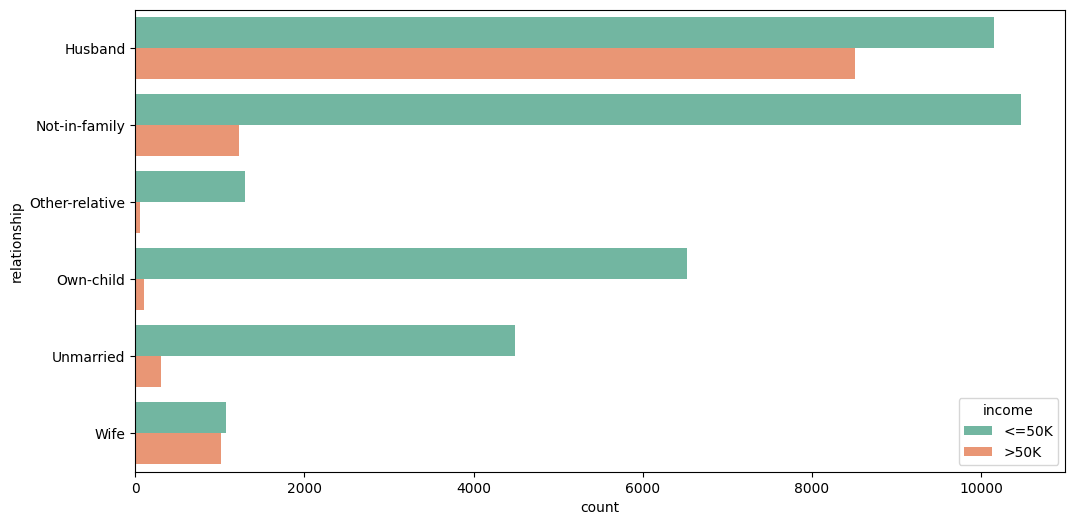

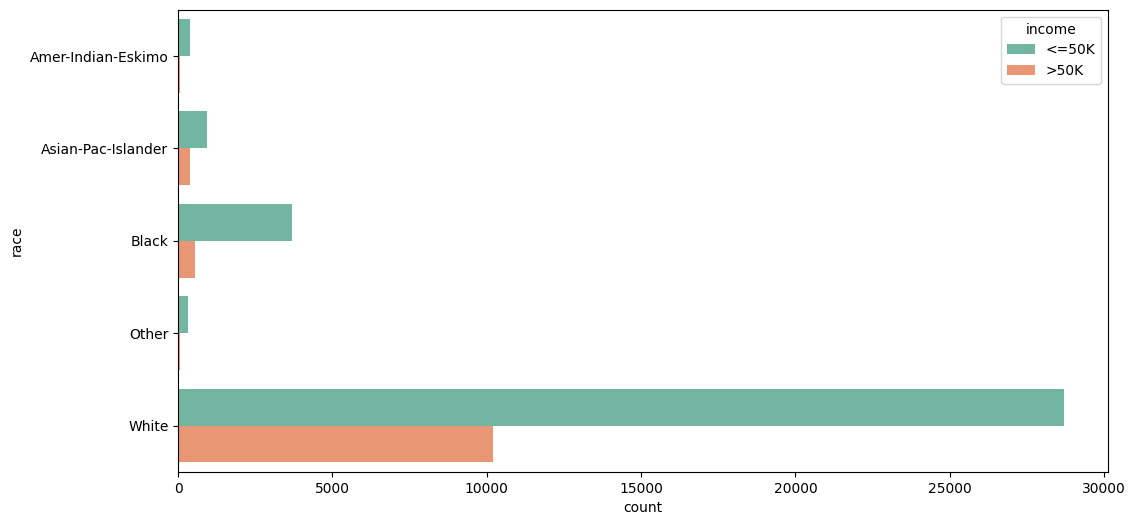

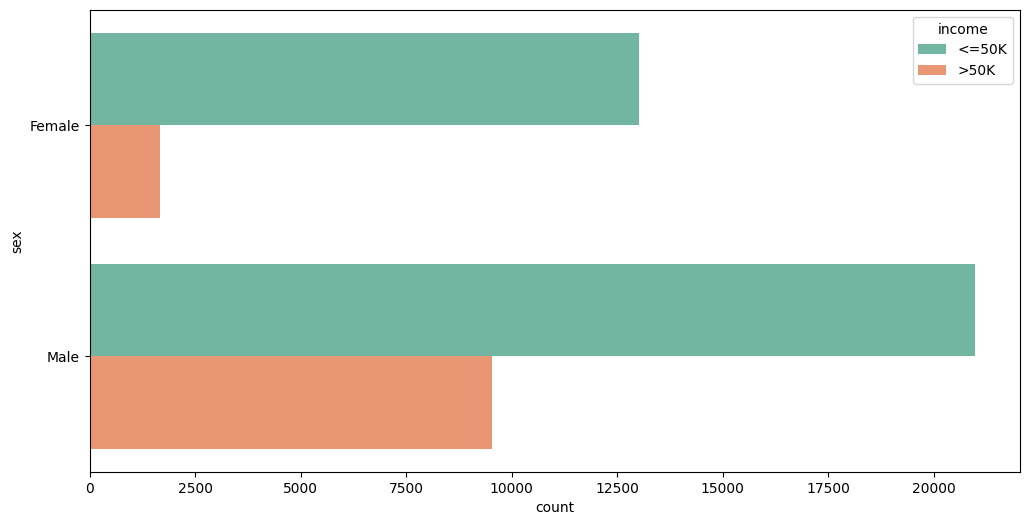

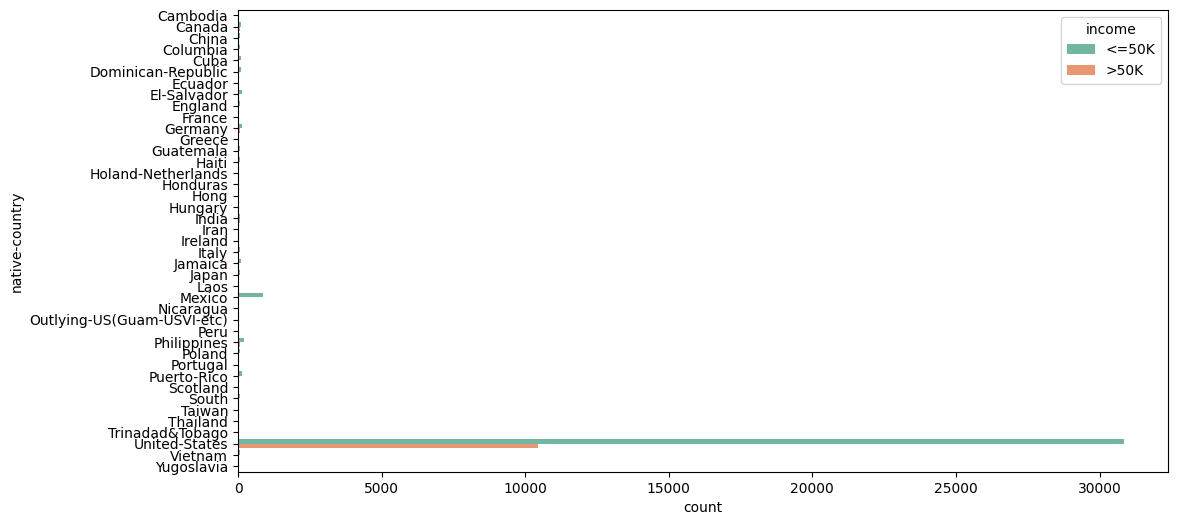

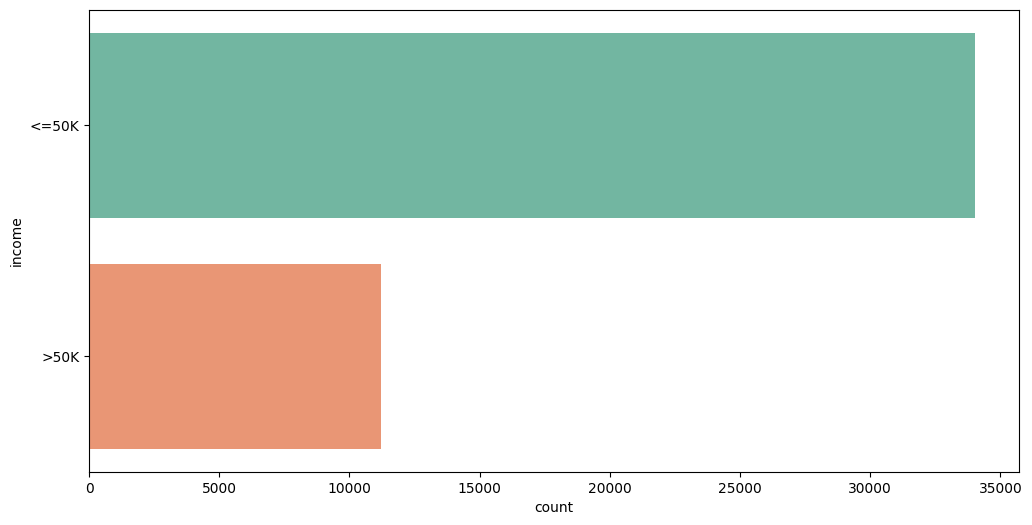

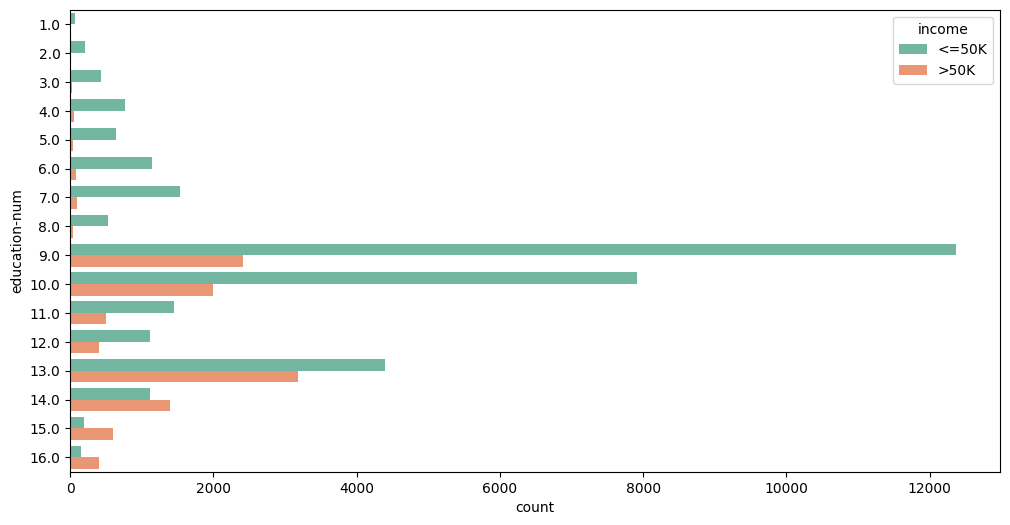

In [ ]:
cat_col.append(census_df[ 'education-num'])
for col in cat_col:
    plt.figure(figsize=(12, 6))

    # Use countplot with hue='income' to compare groups
    sns.countplot(data=census_df, y=col, hue='income', palette='Set2')

In [ ]:
# Clean cat_col to keep only string column names and filter out any accidentally appended Series
cat_col = [col for col in cat_col if isinstance(col, str)]
# We use crosstab to see the exact percentage of >50K and <=50K for each category
for col in cat_col:
    print(f"--- Income Percentage by {col.upper()} ---")

    # normalize='index' converts counts to decimal percentages
    cross_tab = pd.crosstab(census_df[col], census_df['income'], normalize='index')

    # Sort by '>50K' to see which category has the highest percentage of high income
    cross_tab = cross_tab.sort_values(by='>50K', ascending=False)

    # Multiply by 100 and round to 2 decimal places for better readability
    display(round(cross_tab * 100, 2))
    print("\n" + "="*50 + "\n")

--- Income Percentage by WORKCLASS ---


income,<=50K,>50K
workclass,,
Self-emp-inc,44.59,55.41
Federal-gov,60.95,39.05
Local-gov,70.48,29.52
Self-emp-not-inc,72.10,27.90
State-gov,73.28,26.72
Private,78.23,21.77
Without-pay,90.48,9.52




--- Income Percentage by EDUCATION_LEVEL ---


income,<=50K,>50K
education_level,,
Prof-school,24.59,75.41
Doctorate,26.65,73.35
Masters,44.59,55.41
Bachelors,58.02,41.98
Assoc-acdm,73.59,26.41
Assoc-voc,74.27,25.73
Some-college,79.90,20.10
HS-grad,83.66,16.34
12th,92.55,7.45




--- Income Percentage by MARITAL-STATUS ---


...

income,<=50K,>50K
sex,,
Male,68.75,31.25
Female,88.64,11.36




--- Income Percentage by NATIVE-COUNTRY ---


income,<=50K,>50K
native-country,,
Taiwan,54.55,45.45
France,55.56,44.44
India,57.82,42.18
England,60.50,39.50
Iran,60.71,39.29
Canada,63.19,36.81
Greece,63.27,36.73
Japan,65.17,34.83
Yugoslavia,65.22,34.78




--- Income Percentage by INCOME ---


income,<=50K,>50K
income,,
>50K,0.0,100.0
<=50K,100.0,0.0


In [ ]:
census_df.corr(numeric_only=True)

,age,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,0.037623,0.079683,0.059351,0.101992
education-num,0.037623,1.000000,0.126907,0.081711,0.146206
capital-gain,0.079683,0.126907,1.000000,-0.032102,0.083880
capital-loss,0.059351,0.081711,-0.032102,1.000000,0.054195
hours-per-week,0.101992,0.146206,0.083880,0.054195,1.000000


In [ ]:
temp_df = census_df.copy()
temp_df['income_numeric'] = temp_df['income'].map({'<=50K': 0, '>50K': 1}).astype(int)
correlation=temp_df.corr(numeric_only=True)['income_numeric']

<Axes: >

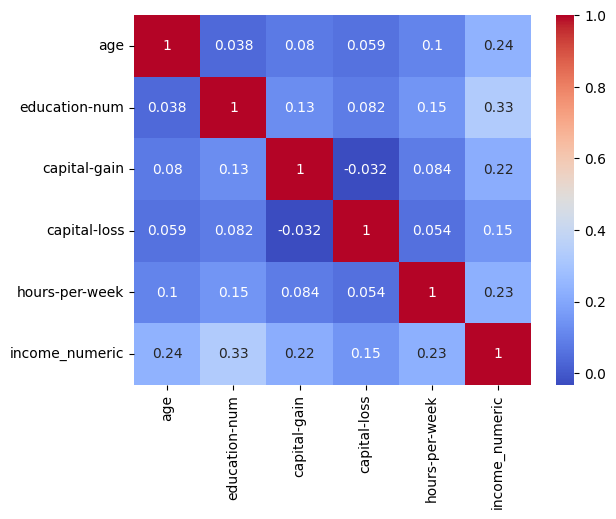

In [ ]:
sns.heatmap(temp_df.corr(numeric_only=True), annot=True, cmap='coolwarm',)

# 📊 Comprehensive Multivariate Analysis Summary

After exploring the relationships between our features and the target variable (`income`) using charts, crosstabs, and a correlation heatmap, here are the key insights:

### 1. The Strongest Income Predictors
- **Education (Highest Impact):** Education has the strongest positive correlation with income (0.33). Our crosstab analysis proved that over 73% of `Doctorate` and `Prof-school` graduates earn `>50K`.
- **Age & Working Hours:** Both show a positive correlation with income (0.24 and 0.23, respectively). The median age for high earners (`>50K`) is around 44, compared to 34 for lower earners. Also, working more hours increases the probability of a higher income.
- **Occupation:** `Exec-managerial` and `Prof-specialty` are clearly the most profitable jobs in this dataset.

### 2. Financial Features (Capital Gain & Loss)
- Both columns consist mostly of zeros. While capital gain has a positive correlation with income, having a high capital gain does not guarantee an income `>50K`. We observed massive outliers (up to 40,000) in the `<=50K` group as well.

### 3. Data Cleaning & Redundancy Check
- We visually and mathematically proved that `education_level` (text) and `education-num` (numbers) provide the exact same information. To avoid redundancy, we will drop the `education_level` column.

### 4. Multicollinearity Check
- The heatmap confirms that our independent numerical variables are not highly correlated with each other (the highest correlation is only 0.15 between education and hours worked). This is excellent because it means our features are independent and will not confuse the future machine learning model.

In [ ]:
census_df.groupby('income', observed=True).mean(numeric_only=True)

,age,education-num,capital-gain,capital-loss,hours-per-week
income,,,,,
<=50K,36.749427,9.630770,149.023407,54.032429,39.372025
>50K,44.006067,11.598501,3991.791504,193.487061,45.690491


## check The outliers

In [ ]:
census_df[census_df['age'] > census_df['age'].quantile(0.99)]


,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
68,79,Private,Some-college,10.0,Married-civ-spouse,Prof-specialty,Other-relative,White,Male,0.0,0.0,20.0,United-States,<=50K
92,76,Private,Masters,14.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,40.0,United-States,>50K
206,90,Private,HS-grad,9.0,Never-married,Other-service,Not-in-family,Black,Male,0.0,2206.0,40.0,United-States,<=50K
211,75,Private,Assoc-voc,11.0,Widowed,Adm-clerical,Not-in-family,White,Female,0.0,0.0,20.0,Columbia,<=50K
293,77,Self-emp-not-inc,Some-college,10.0,Married-civ-spouse,Sales,Husband,White,Male,0.0,0.0,40.0,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44893,84,Private,HS-grad,9.0,Widowed,Priv-house-serv,Not-in-family,White,Female,0.0,0.0,40.0,England,<=50K
44921,80,Private,HS-grad,9.0,Widowed,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,30.0,United-States,<=50K
44957,80,Self-emp-not-inc,7th-8th,4.0,Married-spouse-absent,Farming-fishing,Unmarried,White,Male,0.0,0.0,15.0,United-States,<=50K
45054,83,Private,Some-college,10.0,Divorced,Prof-specialty,Unmarried,White,Female,0.0,0.0,20.0,United-States,<=50K


In [ ]:
census_df[census_df['education-num'] < census_df['education-num'].quantile(0.01)]

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
208,53,Local-gov,Preschool,1.0,Never-married,Machine-op-inspct,Not-in-family,White,Female,0.0,0.0,35.0,United-States,<=50K
386,52,Private,1st-4th,2.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0.0,0.0,40.0,Mexico,<=50K
428,50,Private,1st-4th,2.0,Married-spouse-absent,Craft-repair,Unmarried,White,Male,0.0,0.0,40.0,United-States,<=50K
493,57,Private,1st-4th,2.0,Widowed,Priv-house-serv,Not-in-family,Black,Female,0.0,0.0,30.0,United-States,<=50K
855,33,Private,1st-4th,2.0,Married-spouse-absent,Priv-house-serv,Not-in-family,White,Female,0.0,0.0,40.0,Guatemala,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44340,64,Private,1st-4th,2.0,Married-civ-spouse,Transport-moving,Husband,White,Male,0.0,0.0,40.0,United-States,<=50K
44516,35,Private,Preschool,1.0,Married-civ-spouse,Craft-repair,Husband,White,Male,0.0,0.0,38.0,Mexico,<=50K
44661,48,Private,1st-4th,2.0,Separated,Machine-op-inspct,Other-relative,Black,Male,0.0,0.0,48.0,United-States,<=50K
44765,32,Private,1st-4th,2.0,Never-married,Exec-managerial,Own-child,White,Male,0.0,0.0,21.0,United-States,<=50K


In [ ]:
census_df[census_df['hours-per-week'] > census_df['hours-per-week'].quantile(0.99)]

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
251,50,Self-emp-not-inc,Masters,14.0,Married-civ-spouse,Farming-fishing,Husband,White,Male,2407.0,0.0,98.0,United-States,<=50K
860,37,Private,HS-grad,9.0,Married-civ-spouse,Craft-repair,Husband,White,Male,0.0,0.0,99.0,United-States,>50K
1079,25,Private,Masters,14.0,Married-civ-spouse,Farming-fishing,Not-in-family,White,Male,0.0,0.0,99.0,United-States,>50K
1301,31,Private,Bachelors,13.0,Married-civ-spouse,Sales,Husband,Black,Male,0.0,0.0,90.0,United-States,>50K
1589,24,Private,Masters,14.0,Never-married,Exec-managerial,Own-child,White,Male,6849.0,0.0,90.0,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44427,57,Private,Masters,14.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,7688.0,0.0,84.0,United-States,>50K
44567,43,Self-emp-inc,Some-college,10.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,92.0,United-States,>50K
44993,40,State-gov,HS-grad,9.0,Married-civ-spouse,Protective-serv,Husband,Amer-Indian-Eskimo,Male,0.0,0.0,84.0,United-States,<=50K
45017,59,Self-emp-inc,Prof-school,15.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999.0,0.0,84.0,United-States,>50K


In [ ]:
census_df[census_df['capital-loss'] > census_df['capital-loss'].quantile(0.99)]

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
22,43,Private,11th,7.0,Married-civ-spouse,Transport-moving,Husband,White,Male,0.0,2042.0,40.0,United-States,<=50K
138,64,Private,11th,7.0,Married-civ-spouse,Craft-repair,Husband,White,Male,0.0,2179.0,40.0,United-States,<=50K
206,90,Private,HS-grad,9.0,Never-married,Other-service,Not-in-family,Black,Male,0.0,2206.0,40.0,United-States,<=50K
354,46,Private,5th-6th,3.0,Divorced,Craft-repair,Not-in-family,White,Female,0.0,2339.0,45.0,United-States,<=50K
360,44,Private,Some-college,10.0,Married-civ-spouse,Adm-clerical,Wife,White,Female,0.0,2415.0,6.0,United-States,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44482,47,Self-emp-inc,Prof-school,15.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,0.0,2415.0,55.0,United-States,>50K
44591,65,Private,7th-8th,4.0,Widowed,Priv-house-serv,Not-in-family,White,Female,0.0,3175.0,60.0,Puerto-Rico,<=50K
45024,30,Private,Bachelors,13.0,Never-married,Prof-specialty,Not-in-family,White,Female,0.0,2339.0,50.0,United-States,<=50K
45032,54,Private,Doctorate,16.0,Widowed,Tech-support,Unmarried,White,Male,0.0,2472.0,40.0,United-States,>50K


In [ ]:
census_df[census_df['capital-gain'] > census_df['capital-gain'].quantile(0.99)]

,age,workclass,education_level,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
491,67,Private,Prof-school,15.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,20051.0,0.0,48.0,United-States,>50K
648,46,Private,Doctorate,16.0,Divorced,Prof-specialty,Unmarried,White,Female,25236.0,0.0,65.0,United-States,>50K
1145,54,Self-emp-inc,Prof-school,15.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999.0,0.0,60.0,United-States,>50K
1256,52,Private,HS-grad,9.0,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,99999.0,0.0,40.0,Japan,>50K
1265,65,Private,Masters,14.0,Married-civ-spouse,Sales,Husband,White,Male,20051.0,0.0,40.0,United-States,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44973,61,Self-emp-not-inc,Masters,14.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999.0,0.0,30.0,United-States,>50K
44982,36,Private,Bachelors,13.0,Never-married,Prof-specialty,Not-in-family,White,Male,99999.0,0.0,45.0,United-States,>50K
44987,42,Private,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999.0,0.0,42.0,United-States,>50K
45017,59,Self-emp-inc,Prof-school,15.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999.0,0.0,84.0,United-States,>50K


## Outliers Real Data

In [ ]:
# Check if education_level and education-num represent the exact same thing
# We drop duplicates to see every unique combination of both columns
edu_relation = census_df[['education_level', 'education-num']].drop_duplicates()

# Sort by the number to see the logical order (from lowest to highest education)
display(edu_relation.sort_values(by='education-num'))

,education_level,education-num
208,Preschool,1.0
386,1st-4th,2.0
52,5th-6th,3.0
14,7th-8th,4.0
6,9th,5.0
204,10th,6.0
3,11th,7.0
385,12th,8.0
2,HS-grad,9.0
10,Some-college,10.0


In [ ]:
census_df.shape

(45222, 14)

## Select Features and Target

In [ ]:
x=census_df.drop(['income','education_level'], axis=1)
y=census_df['income']

x.shape, y.shape

((45222, 12), (45222,))

In [ ]:
x.head()

,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States
1,50,Self-emp-not-inc,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States
2,38,Private,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States
3,53,Private,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States
4,28,Private,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba


In [ ]:
y.head(20)

,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K
5,<=50K
6,<=50K
7,>50K
8,>50K
9,>50K


## 2. Split the Data
Create a reproducible 80/20 training and held-out evaluation split, stratified by `income` so both `>50K` and `<=50K` groups are represented proportionally. Keep the held-out labels out of preprocessing, fitting, and grid search. Treat `test_census.csv` as a separate unlabeled prediction input, not as this evaluation split.

In [ ]:

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_train.shape, x_test.shape, y_train.shape, y_test.shape



((36177, 12), (9045, 12), (36177,), (9045,))

In [ ]:
print(y_train.value_counts())
print(y_test.value_counts())

income
<=50K    27211
>50K      8966
Name: count, dtype: int64
income
<=50K    6803
>50K     2242
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)


In [ ]:
Y_train_df=pd.DataFrame(y_train_encoded, columns=['income'])
Y_test_df=pd.DataFrame(y_test_encoded, columns=['income'])
print(Y_train_df.value_counts())
print(Y_test_df.value_counts())

income
0         27211
1          8966
Name: count, dtype: int64
income
0         6803
1         2242
Name: count, dtype: int64


In [ ]:
outer_test_census_df = pd.read_csv('test_census.csv')
outer_test_census_df.head()
outer_test_census_df.shape

(45222, 14)

### 🛡️ Defensive Programming: Building a Production-Ready Architecture

In a real-world deployment environment, we cannot trust incoming data. As seen above, our external `test_census.csv` has 14 columns, while our training data only has 12. Furthermore, users might input logically incorrect data (e.g., negative age or text instead of numbers). If we feed this directly to the model, the entire system will crash.

To prevent this and build a "bulletproof" pipeline, I designed a **Two-Stage Defense Architecture**:

**1. Stage 1: The API Gatekeeper (Logical Validation via Pydantic)**
Before data even touches the Machine Learning pipeline, it must pass through our `CensusInput` Pydantic schema (defined in `ml_utils.py`). This acts as an API validator that checks the data row by row to ensure it follows business logic:
* Enforces correct data types.
* Checks logical ranges (e.g., Age must be 17-90, Working hours cannot be negative).
* Fills missing categorical data with 'Unknown'.
* Drops or flags completely corrupted rows.

**2. Stage 2: The ML Gatekeeper (Structural Alignment via Custom Transformer)**
Scikit-Learn pipelines require exact column structures. Therefore, I built a custom `FeatureAligner` transformer that runs at the very beginning of the ML pipeline. Its job is to dynamically:
* **Drop** any extra columns not seen during training.
* **Add** missing numeric or categorical columns with appropriate default values.
* **Reorder** all columns to perfectly match the training dataset.

Together, Pydantic ensures the data is *logically* sound, and the Custom Transformer ensures the data is *structurally* sound. This guarantees that our model will never fail in production.

In [ ]:
col_to_reshaping = ['capital-gain', 'capital-loss','age','hours-per-week']
col_to_scaling=['age','education-num','capital-gain','capital-loss','hours-per-week']
col_to_encoder=['workclass','marital-status','occupation','relationship','race','sex','native-country']

In [ ]:
from ml_utils import describe_with_whisker
describe_with_whisker(x_train)

,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
count,36177.000000,36177,36177.000000,36177,36177,36177,36177,36177,36177.000000,36177.000000,36177.000000,36177
unique,NaN,7,NaN,7,14,6,5,2,NaN,NaN,NaN,41
top,NaN,Private,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States
freq,NaN,26601,NaN,16876,4823,14984,31139,24466,NaN,NaN,NaN,33020
mean,38.568206,NaN,10.119523,NaN,NaN,NaN,NaN,NaN,1093.728638,89.604912,40.971031,NaN
std,13.193772,NaN,2.560815,NaN,NaN,NaN,NaN,NaN,7433.572754,406.582275,11.996550,NaN
min,17.000000,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN
25%,28.000000,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN
50%,37.000000,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN
75%,47.000000,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN


In [ ]:
from sklearn.preprocessing import PowerTransformer
yeo_johnson_transformer = PowerTransformer(method='yeo-johnson', standardize=False)
xf_train_transformed = yeo_johnson_transformer.fit_transform(x_train[col_to_reshaping])
X_train_reshaped=pd.DataFrame(xf_train_transformed, columns=col_to_reshaping)
describe_with_whisker(X_train_reshaped)


,capital-gain,capital-loss,age,hours-per-week
count,36177.000000,36177.000000,36177.000000,36177.000000
mean,0.062349,0.017291,5.305332,36.725666
std,0.205951,0.077031,0.691454,10.414447
min,-0.000000,-0.000000,3.893221,0.985355
25%,0.000000,0.000000,4.776346,35.944126
50%,0.000000,0.000000,5.314897,35.944126
75%,0.000000,0.000000,5.804018,40.272053
max,0.742478,0.360341,7.264282,86.139122
IQR,0.000000,0.000000,1.027672,4.327927
1.5IQR,0.000000,0.000000,1.541508,6.491890


## 4. Normalizing Numerical Features
Scale numeric columns such as `age`, `education-num`, `capital-gain`, `capital-loss`, and `hours-per-week` when it benefits the chosen learner. Compare a method such as MinMax scaling with another appropriate scaler, and explain why scale-sensitive models may benefit while tree-based models often do not. Fit scaling only within the training pipeline.

In [ ]:
col_only_scaling = ['education-num']
df_only_scaling = x_train[col_only_scaling]

df_combined_for_scaling = pd.concat([X_train_reshaped, df_only_scaling], axis=1)

from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
xf_train_scaled= scaler.fit_transform(df_combined_for_scaling)
describe_with_whisker(pd.DataFrame(xf_train_scaled, columns=df_combined_for_scaling.columns))


,capital-gain,capital-loss,age,hours-per-week,education-num
count,36177.000000,36177.000000,36177.000000,36177.000000,36177.000000
mean,0.062349,0.017291,-0.009307,0.180581,0.029881
std,0.205951,0.077031,0.672840,2.406520,0.640205
min,-0.000000,-0.000000,-1.383394,-8.077487,-2.250000
25%,0.000000,0.000000,-0.524049,0.000000,-0.250000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.475951,1.000000,0.750000
max,0.742478,0.360341,1.896894,11.597931,1.500000
IQR,0.000000,0.000000,1.000000,1.000000,1.000000
1.5IQR,0.000000,0.000000,1.500000,1.500000,1.500000


In [ ]:
# TODO: Implement task 4

## 5. Transform Categorical Features
Convert columns such as `workclass`, `education_level`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, and `native-country` into model-ready features. Consider one-hot encoding and the feature-count impact of categories such as country; configure a strategy for categories not seen during training. Encode the binary target consistently as `<=50K` and `>50K`, and record which value represents the positive class.

In [ ]:
# TODO: Implement task 5
col_to_encoder=['workclass','marital-status','occupation','relationship','race','sex','native-country']
col_to_onehoter = ['workclass', 'marital-status', 'occupation', 'relationship', 'race']

col_to_binary = ['native-country']
col_to_ordinal = ['sex']
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
xf_train_encoded = one_hot_encoder.fit_transform(x_train[col_to_onehoter])
onehot_df = pd.DataFrame(xf_train_encoded, columns=one_hot_encoder.get_feature_names_out(col_to_onehoter))
display(onehot_df)



,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Divorced,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,...,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36172,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
36173,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
36174,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
36175,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
# Install category_encoders if you haven't already
!pip install -q category_encoders

from category_encoders import BinaryEncoder
binary_encoder = BinaryEncoder()
xf_train_binary_encoded = binary_encoder.fit_transform(x_train[col_to_binary])
binary_df = pd.DataFrame(xf_train_binary_encoded)
display(binary_df)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 2.9 MB/s eta 0:00:00


,native-country_0,native-country_1,native-country_2,native-country_3,native-country_4,native-country_5
11772,0,0,0,0,0,1
22476,0,0,0,0,0,1
17763,0,0,0,0,0,1
22789,0,0,0,0,0,1
26558,0,0,0,0,1,0
...,...,...,...,...,...,...
29107,0,0,0,0,0,1
23866,0,1,1,1,0,1
15769,0,0,0,0,0,1
33553,0,0,0,0,0,1


In [ ]:
x_train['sex'].value_counts()

,count
sex,
Male,24466
Female,11711


In [ ]:
ordinal_encoder = OrdinalEncoder()
xf_train_ordinal_encoded = ordinal_encoder.fit_transform(x_train[col_to_ordinal])
ordinal_df = pd.DataFrame(xf_train_ordinal_encoded, columns=col_to_ordinal)
display(ordinal_df.value_counts())

,count
sex,
1.0,24466
0.0,11711


## 7. Create a Processing Pipeline
Use a `ColumnTransformer` to apply numeric and categorical preprocessing to their respective census columns, then combine it with each classifier in a scikit-learn `Pipeline`. Keeping transformations inside the pipeline ensures cross-validation learns imputers, scalers, skew transforms, and category encoders from each training fold and can safely handle unseen categories at prediction time.

In [ ]:
!pip install -q category_encoders

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, RobustScaler, OneHotEncoder, OrdinalEncoder
from category_encoders import BinaryEncoder
from sklearn.impute import SimpleImputer

# 1. Group columns based on what they need
# These numerical columns need to fix the shape (reshape) and then scale
num_reshape_cols = ['age', 'hours-per-week', 'capital-gain', 'capital-loss']

# This numerical column only needs scaling (no reshaping)
num_scale_only_cols = ['education-num']

# These categorical columns need One-Hot Encoding
cat_onehot_cols = ['workclass', 'marital-status', 'occupation', 'relationship', 'race']

# This categorical column needs Ordinal Encoding
cat_ordinal_cols = ['sex']

# This categorical column needs Binary Encoding
cat_binary_cols = ['native-country']

# 2. Build complete pipelines for EACH data type
# Every pipeline MUST start with an Imputer to clean the data before further processing

# --- Numerical Pipelines ---
num_reshape_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Step 1: Impute missing values with median
    ('reshaper', PowerTransformer(method='yeo-johnson', standardize=False)), # Step 2: Fix skewness
    ('scaler', RobustScaler()) # Step 3: Scale data to handle outliers
])

num_scale_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Step 1: Impute missing values with median
    ('scaler', RobustScaler()) # Step 2: Scale data
])

# --- Categorical Pipelines ---
cat_onehot_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Step 1: Impute missing values with mode
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore')) # Step 2: One-Hot Encoding
])

cat_ordinal_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Step 1: Impute missing values with mode
    ('encoder', OrdinalEncoder()) # Step 2: Ordinal Encoding
])

cat_binary_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Step 1: Impute missing values with mode
    ('encoder', BinaryEncoder()) # Step 2: Binary Encoding
])

# 3. Combine everything into the main ColumnTransformer
# Distribute the columns to their respective pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num_reshape', num_reshape_pipe, num_reshape_cols),
        ('num_scale', num_scale_pipe, num_scale_only_cols),
        ('cat_onehot', cat_onehot_pipe, cat_onehot_cols),
        ('cat_ordinal', cat_ordinal_pipe, cat_ordinal_cols),
        ('cat_binary', cat_binary_pipe, cat_binary_cols)
    ],
    remainder='passthrough' # Keep remaining columns untouched
)

In [2]:

from custom_trasformer import FeatureAligner


In [ ]:
# 1. IMPORTANT: Import Pipeline from imblearn, NOT sklearn!
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score

# 2. Define the 3 models with a fixed random state
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
    }

# Dictionary to save the results (Train and Test)
model_results = {}
trained_pipelines = {}

# 3. Loop through each model to build, train, and test
for model_name, model_instance in models.items():
    print(f"Training {model_name} with SMOTE...")

    # 4. Build the FULL imbalanced pipeline (The Bulletproof version)
    final_pipeline = ImbPipeline(steps=[
        ('feature_aligner', FeatureAligner()), # Step 1: Fix structure
        ('preprocessor', preprocessor),        # Step 2: Math and Encoding
        ('smote', SMOTE(random_state=42)),     # Step 3: Balance classes (runs ONLY during fit)
        ('classifier', model_instance)         # Step 4: Train model
    ])

    # 5. Train the pipeline on training data
    final_pipeline.fit(x_train, y_train_encoded) ## learn from book C

    # 6. Make predictions on BOTH Train and Test data
    y_train_pred = final_pipeline.predict(x_train) # To check if the model memorized the data ##  Test Exam on Book C
    y_test_pred = final_pipeline.predict(x_test)   # To check real performance ##             ##  Test Exam on BOOK A

    # 7. Calculate accuracies
    train_accuracy = accuracy_score(y_train_encoded, y_train_pred)
    test_accuracy = accuracy_score(y_test_encoded, y_test_pred)
    trained_pipelines[model_name] = final_pipeline
    train_f1=f1_score(y_train_encoded, y_train_pred)
    test_f1=f1_score(y_test_encoded, y_test_pred)
    train_recall=recall_score(y_train_encoded, y_train_pred)
    test_recall=recall_score(y_test_encoded, y_test_pred)
    train_precision=precision_score(y_train_encoded, y_train_pred)
    test_precision=precision_score(y_test_encoded, y_test_pred)
    # 8. Save both results
    model_results[model_name] = {
        'Train Accuracy': train_accuracy,
        'Test Accuracy': test_accuracy,
        'Train F1': train_f1,
        'Test F1': test_f1,
        'train_recall': train_recall,
        'test_recall': test_recall,
        'train_precision': train_precision,
        'test_precision': test_precision
    }


    print(f"Done! Train: {train_accuracy:.4f} | Test: {test_accuracy:.4f}\n")

# 9. Print the final comparison table
print("=== Final Models Comparison (Train vs Test) ===")
for name, scores in model_results.items():
    print(f"{name}:")
    print(f"  - Train Accuracy = {scores['Train Accuracy']:.4f}")
    print(f"  - Test Accuracy  = {scores['Test Accuracy']:.4f}")
    print(f"  - Train F1       = {scores['Train F1']:.4f}")
    print(f"  - Test F1        = {scores['Test F1']:.4f}")
    print(f"  - Train Recall   = {scores['train_recall']:.4f}")
    print(f"  - Test Recall    = {scores['test_recall']:.4f}")
    print(f"  - Train Precision= {scores['train_precision']:.4f}")
    print(f"  - Test Precision = {scores['test_precision']:.4f}")
    print("-" * 30)

Training Logistic Regression with SMOTE...
Done! Train: 0.8029 | Test: 0.8032

Training Random Forest with SMOTE...
Done! Train: 0.9707 | Test: 0.8346

Training Gradient Boosting with SMOTE...
Done! Train: 0.8298 | Test: 0.8248

=== Final Models Comparison (Train vs Test) ===
Logistic Regression:
  - Train Accuracy = 0.8029
  - Test Accuracy  = 0.8032
  - Train F1       = 0.6780
  - Test F1        = 0.6753
  - Train Recall   = 0.8374
  - Test Recall    = 0.8256
  - Train Precision= 0.5696
  - Test Precision = 0.5713
------------------------------
Random Forest:
  - Train Accuracy = 0.9707
  - Test Accuracy  = 0.8346
  - Train F1       = 0.9415
  - Test F1        = 0.6686
  - Train Recall   = 0.9520
  - Test Recall    = 0.6731
  - Train Precision= 0.9313
  - Test Precision = 0.6642
------------------------------
Gradient Boosting:
  - Train Accuracy = 0.8298
  - Test Accuracy  = 0.8248
  - Train F1       = 0.7046
  - Test F1        = 0.6932
  - Train Recall   = 0.8189
  - Test Recall   

Plotting matrices for Logistic Regression...
Plotting matrices for Random Forest...
Plotting matrices for Gradient Boosting...


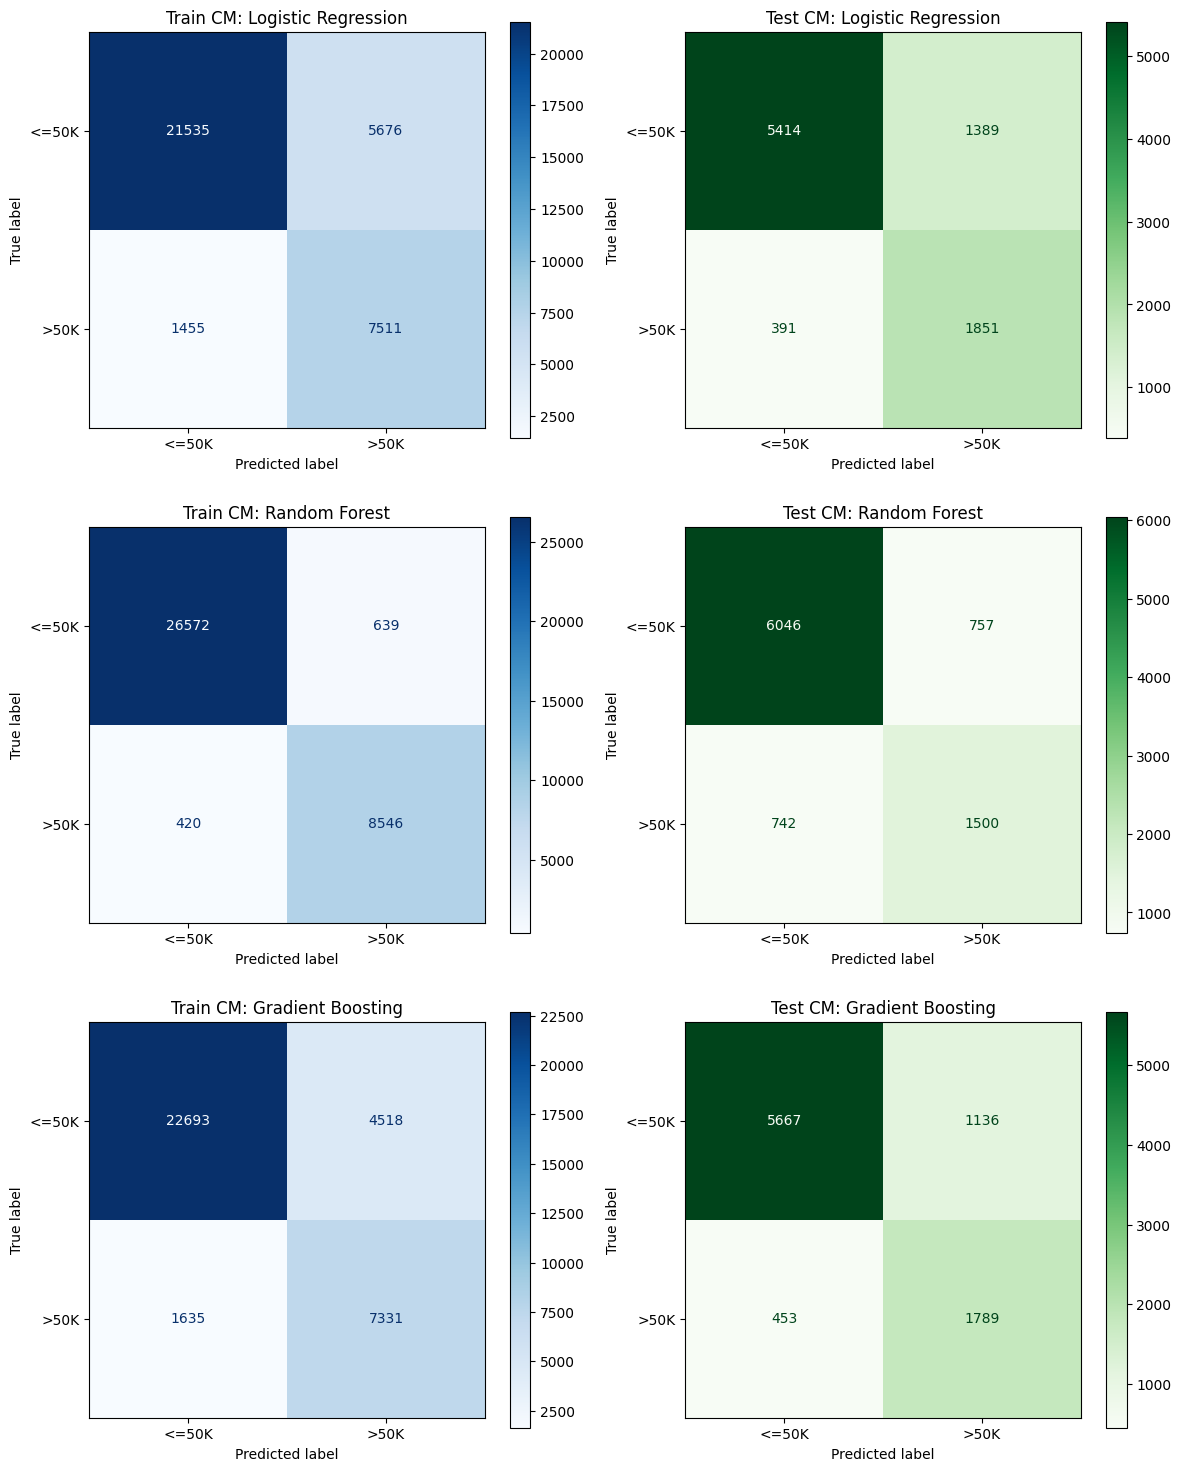

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Create a large figure to hold all 6 matrices
# 3 rows (for the 3 models) and 2 columns (Train vs Test)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 15))

# 2. Loop through the SAVED trained pipelines
# 'trained_pipelines' is the dictionary you saved in the previous cell
for row_idx, (model_name, trained_pipe) in enumerate(trained_pipelines.items()):
    print(f"Plotting matrices for {model_name}...")

    # 3. Make predictions using the ALREADY TRAINED pipeline
    # No .fit() is used here at all!
    y_train_pred = trained_pipe.predict(x_train)
    y_test_pred = trained_pipe.predict(x_test)

    # 4. Calculate confusion matrices
    cm_train = confusion_matrix(y_train_encoded, y_train_pred)
    cm_test = confusion_matrix(y_test_encoded, y_test_pred)

    # 5. Plot Train Matrix on the Left column (row_idx, 0)
    disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=['<=50K', '>50K'])
    disp_train.plot(ax=axes[row_idx, 0], cmap='Blues', values_format='d')
    axes[row_idx, 0].set_title(f"Train CM: {model_name}")

    # 6. Plot Test Matrix on the Right column (row_idx, 1)
    disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['<=50K', '>50K'])
    disp_test.plot(ax=axes[row_idx, 1], cmap='Greens', values_format='d')
    axes[row_idx, 1].set_title(f"Test CM: {model_name}")

# 7. Adjust layout so plots do not overlap and show them
plt.tight_layout()
plt.show()

### 📊 Why PR Curve instead of Baseline Metrics?

We cannot fully trust the initial baseline results (like Accuracy or default F1-score) for the following reasons:

* **Imbalanced Dataset:** We have many non-donators and very few donators. Standard metrics can look good even if the model fails to find the donators.
* **The Default 0.5 Threshold:** Baseline models evaluate predictions at a strict 0.5 threshold. In our case, this might force the model to classify most people as "poor" to play it safe.
* **Full Evaluation:** The Precision-Recall (PR) Curve tests the models across **all thresholds**, showing their raw power to separate the two classes (measured by Average Precision - AP).
* **Business Trade-off:** The curve helps us visually balance **Precision** (reducing false calls) and **Recall** (finding more donators), allowing us to pick the best custom threshold for our business needs later.

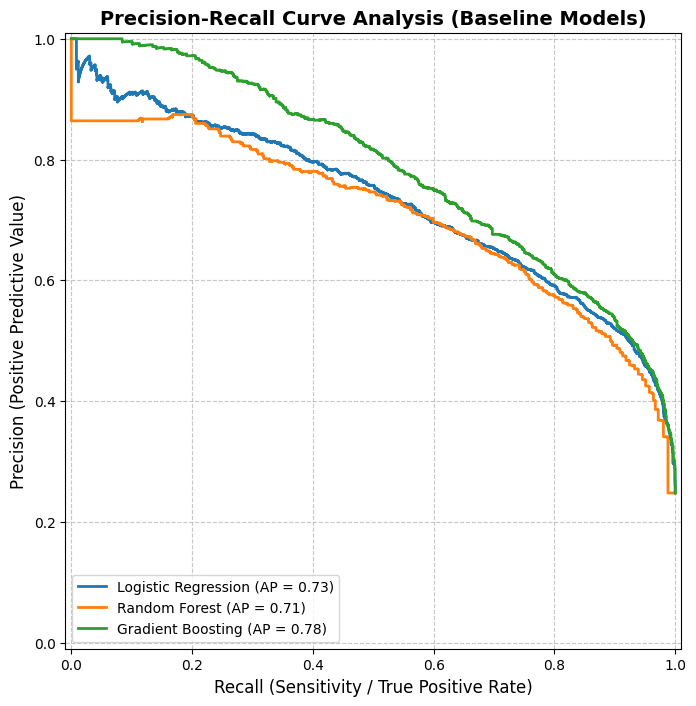

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

# Initialize the matplotlib figure and axes for the PR Curve evaluation
fig, ax = plt.subplots(figsize=(10, 8))

# Iterate over the pre-trained pipelines from the baseline evaluation phase
for model_name, pipeline in trained_pipelines.items():

    # Extract predicted probabilities for the minority/positive class (Income > 50K).
    # Utilizing probabilities rather than hard predictions (0 or 1) is essential
    # to evaluate the model's discriminative power across all possible thresholds.
    y_score = pipeline.predict_proba(x_test)[:, 1]

    # Generate and plot the Precision-Recall curve.
    # The PR curve is highly preferred over the ROC curve here due to the
    # severe class imbalance in the target variable, offering a more robust
    # assessment of the False Positive vs. False Negative trade-off.
    PrecisionRecallDisplay.from_predictions(
        y_test_encoded,
        y_score,
        name=model_name,
        ax=ax,
        linewidth=2
    )

# Configure plot aesthetics, statistical labels, and legend
plt.title("Precision-Recall Curve Analysis (Baseline Models)", fontsize=14, fontweight='bold')
plt.xlabel("Recall (Sensitivity / True Positive Rate)", fontsize=12)
plt.ylabel("Precision (Positive Predictive Value)", fontsize=12)
plt.legend(loc="lower left", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)

# Display the final comparative visualization
plt.show()

Tuning Logistic Regression (Balanced Weights, No SMOTE)...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Tuning Gradient Boosting (With SMOTE)...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

=== Best Parameters Found ===
Logistic Regression: {'classifier__C': 1, 'classifier__penalty': 'l1'}
Gradient Boosting: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 300}


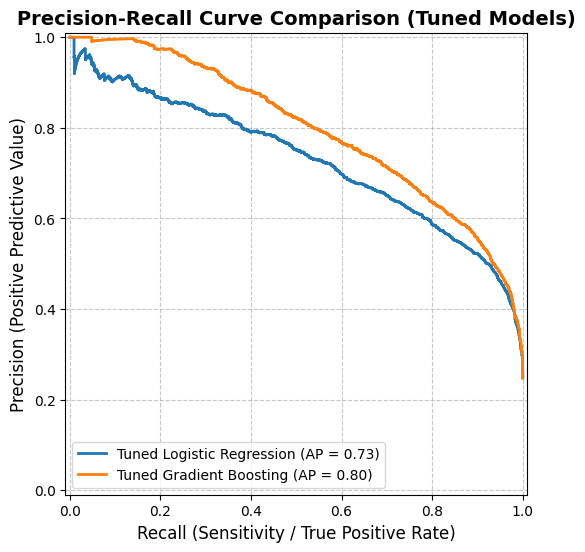

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

# ==========================================
# 1. Define Parameter Grids (Hyperparameters)
# ==========================================

# Logistic Regression Grid: Tuning Regularization strength (C) and penalty type (L1/L2)
lr_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2']
}

# Gradient Boosting Grid: Tuning tree complexity and learning speed
gb_param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__max_depth': [3, 4, 5]
}

# ==========================================
# 2. Setup ImbPipelines
# ==========================================
# Assuming "feature_aligner" and "preprocessor" are defined in previous cells

# Logistic Regression Pipeline: NO SMOTE
# Using class_weight='balanced' to handle imbalance dynamically inside the cost function.
# Using solver='liblinear' to allow the L1 penalty (Lasso).
lr_pipeline = ImbPipeline(steps=[
    ("feature_aligner", FeatureAligner()),
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight='balanced',
        solver='liblinear',
        random_state=42,
        max_iter=1000
    ))
])

# Gradient Boosting Pipeline: WITH SMOTE
# SMOTE is essential here to generate synthetic samples for the minority class before feeding to trees.
gb_pipeline = ImbPipeline(steps=[
    ("feature_aligner", FeatureAligner()),
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

# ==========================================
# 3. Initialize GridSearchCV (Optimized for PR Curve)
# ==========================================
# CRITICAL: scoring='average_precision' ensures we optimize for the Area Under the PR Curve.

grid_lr = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    cv=5,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)

grid_gb = GridSearchCV(
    gb_pipeline,
    gb_param_grid,
    cv=5,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)

# ==========================================
# 4. Fit the Models
# ==========================================
print("Tuning Logistic Regression (Balanced Weights, No SMOTE)...")
grid_lr.fit(x_train, y_train_encoded)

print("\nTuning Gradient Boosting (With SMOTE)...")
grid_gb.fit(x_train, y_train_encoded)

# Print the winning parameters
print("\n=== Best Parameters Found ===")
print(f"Logistic Regression: {grid_lr.best_params_}")
print(f"Gradient Boosting: {grid_gb.best_params_}")

# ==========================================
# 5. Evaluate and Plot Final PR Curves
# ==========================================
fig, ax = plt.subplots(figsize=(10, 6))

# Extract the best trained estimators
best_lr_model = grid_lr.best_estimator_
best_gb_model = grid_gb.best_estimator_

# Plot PR Curves
PrecisionRecallDisplay.from_estimator(
    best_lr_model, x_test, y_test_encoded,
    name="Tuned Logistic Regression",
    ax=ax, linewidth=2
)

PrecisionRecallDisplay.from_estimator(
    best_gb_model, x_test, y_test_encoded,
    name="Tuned Gradient Boosting",
    ax=ax, linewidth=2
)

# Plot aesthetics
plt.title("Precision-Recall Curve Comparison (Tuned Models)", fontsize=14, fontweight='bold')
plt.xlabel("Recall (Sensitivity / True Positive Rate)", fontsize=12)
plt.ylabel("Precision (Positive Predictive Value)", fontsize=12)
plt.legend(loc="lower left", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Optimal Threshold

In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# ==========================================
# 1. Threshold Optimization (Business Logic)
# ==========================================
print("Extracting Optimal Threshold for Business Decision...\n")

# Get probability scores for the positive class (Donators) from the BEST model
y_scores = best_gb_model.predict_proba(x_test)[:, 1]

# Extract all possible precisions, recalls, and thresholds from the PR Curve
precisions, recalls, thresholds = precision_recall_curve(y_test_encoded, y_scores)

# Calculate F1-Score for EVERY threshold
# Note: We add a tiny value (1e-10) to the denominator to prevent division by zero errors
f1_scores = (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)

# Find the index of the highest F1-Score
optimal_idx = np.argmax(f1_scores)

# Extract the winning metrics
optimal_threshold = thresholds[optimal_idx]
optimal_precision = precisions[optimal_idx]
optimal_recall = recalls[optimal_idx]
max_f1 = f1_scores[optimal_idx]

# ==========================================
# 2. Print the Business Insights
# ==========================================
print("=== Optimal Business Threshold Discovered ===")
print(f"Optimal Probability Threshold: {optimal_threshold:.4f}")
print(f"Expected Precision (Accuracy of our calls): {optimal_precision:.4f}")
print(f"Expected Recall (Percentage of rich people found): {optimal_recall:.4f}")
print(f"Maximum F1-Score Achieved: {max_f1:.4f}\n")

# ==========================================
# 3. Apply the new Threshold to final predictions
# ==========================================
# Instead of relying on model.predict(), we manually apply our discovered threshold
# If probability >= optimal_threshold, classify as 1 (Donator), else 0
final_business_predictions = (y_scores >= optimal_threshold).astype(int)

print(f"Successfully applied the optimal threshold ({optimal_threshold:.4f}) to the final test set predictions.")

Extracting Optimal Threshold for Business Decision...

=== Optimal Business Threshold Discovered ===
Optimal Probability Threshold: 0.4711
Expected Precision (Accuracy of our calls): 0.6816
Expected Recall (Percentage of rich people found): 0.7484
Maximum F1-Score Achieved: 0.7134

Successfully applied the optimal threshold (0.4711) to the final test set predictions.


Initializing SHAP Explainer (Opening the Black Box)...


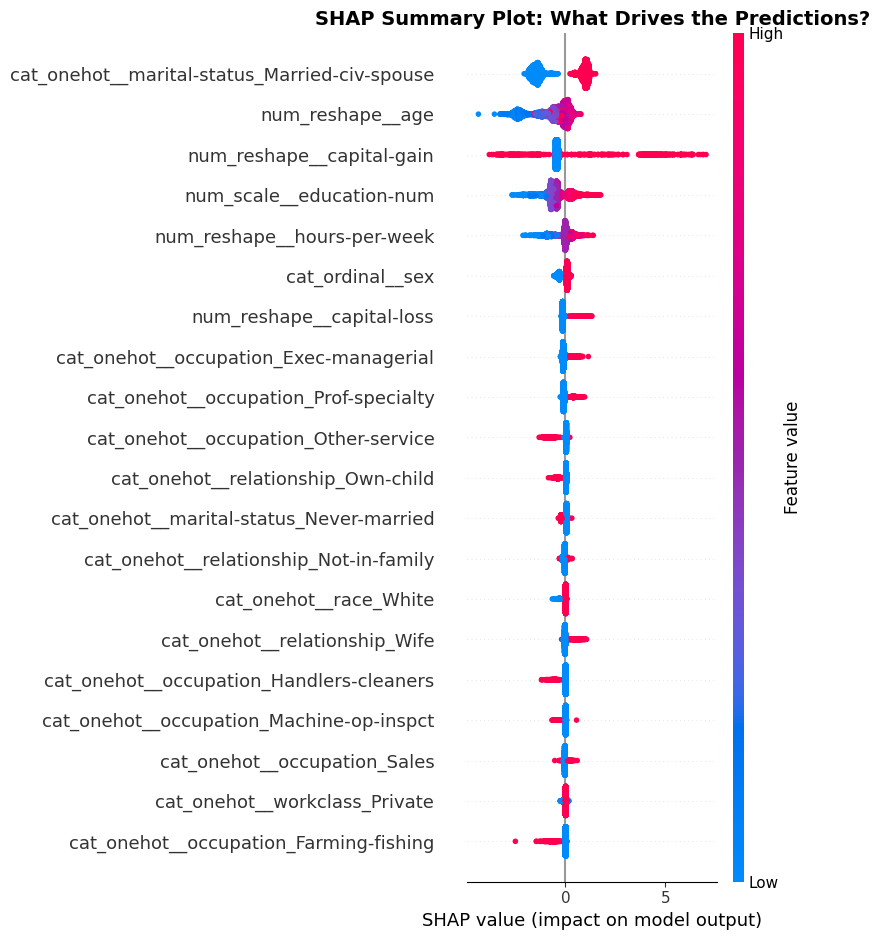

In [ ]:
# 1. Install SHAP if it's not already installed (uncomment the line below if needed)
# !pip install shap

import shap
import matplotlib.pyplot as plt

print("Initializing SHAP Explainer (Opening the Black Box)...")

# 2. Extract the actual model and preprocessor from your tuned pipeline
# Note: We use the names you defined in your pipeline (e.g., 'preprocessor' and 'classifier')
preprocessor = best_gb_model.named_steps['preprocessor']
gb_classifier = best_gb_model.named_steps['classifier']

# 3. Transform the X_test data (SHAP needs the numerical, processed data, not the raw text)
X_test_transformed = preprocessor.transform(x_test)

# Convert to dense array if the preprocessor outputs a sparse matrix
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Get the actual feature names after preprocessing (e.g., OneHotEncoding creates new columns)
feature_names = preprocessor.get_feature_names_out()

# 4. Create the TreeExplainer (Optimized for Gradient Boosting / Random Forest)
explainer = shap.TreeExplainer(gb_classifier)

# Calculate SHAP values (This might take a minute depending on data size)
shap_values = explainer.shap_values(X_test_transformed)

# 5. Plot the SHAP Summary Plot
plt.figure(figsize=(10, 6))
plt.title("SHAP Summary Plot: What Drives the Predictions?", fontsize=14, fontweight='bold')

# The summary plot shows feature importance and the direction of the impact
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names)

### 📊 Business Insights & Ideal Donor Profile

Based on the **SHAP (SHapley Additive exPlanations)** analysis, we successfully unlocked the model's "black box" to understand the key drivers behind its predictions. The data reveals clear demographic patterns for identifying high-potential donors.

To maximize the call center's ROI (Return on Investment) and minimize wasted efforts, the marketing strategy should heavily target the following ideal donor profile:

* **Marital Status:** Married individuals (`Married-civ-spouse`) are by far the strongest demographic. Being married is the highest-ranking predictor for having a high income and the capacity to donate.
* **Age:** Older individuals show a significantly higher probability of being donors compared to younger age groups, reflecting greater financial stability and accumulated wealth.
* **Education Level:** A higher number of educational years (`education-num`) strongly and positively correlates with a higher likelihood of donation.
* **Secondary Indicators:** Individuals with recorded capital gains (`capital-gain`) and those working longer hours (`hours-per-week`) also represent high-value targets.

**💡 Final Recommendation:**
By combining these demographic insights with our customized probability threshold (**0.47**), the organization can surgically target its outreach campaigns. We can confidently advise the call center to prioritize older, married professionals with higher education, ensuring a higher Precision rate and saving hundreds of unproductive hours.

---

### 🚀 Next Steps & Future Iterations

Although the current model achieved a solid **Average Precision (AP) of 0.80** and we successfully optimized the business threshold to maximize the F1-Score, the marginal improvement from hyperparameter tuning suggests that the `GradientBoostingClassifier` has reached its performance plateau on this current dataset.

To break through this performance ceiling, following the iterative nature of the Machine Learning lifecycle, the recommended next steps would involve looping back to earlier stages:

1. **Iterate back to Step 2 (Feature Engineering & Selection):**
   * **Dimensionality Reduction:** Based on the SHAP analysis, we should drop non-impactful features ( low-importance categories) to reduce noise and training time.
   * **Feature Creation:** We can engineer new features, such as combining `capital-gain` and `capital-loss` into a `net_capital` feature, or grouping `age` into categorical bins to help the model find deeper patterns.

2. **Iterate back to Step 4 (Model Selection):**
   * **Advanced Boosting Algorithms:** We should replace the standard sklearn Gradient Boosting with more robust, state-of-the-art algorithms like **XGBoost** or **LightGBM**. These models are mathematically designed to handle complex, imbalanced datasets more efficiently and often yield higher performance metrics.

By applying these iterative improvements, we expect to further push the boundaries of the model's Precision and Recall, ultimately delivering even higher value to the business.

## 15. Save the Model Weights
Save the best tuned, fitted preprocessing-and-classifier pipeline as one artifact (for example, with `joblib`) so new census rows receive the same cleaning, transformations, and encoding used in training. Record the artifact path and the selected model. As a final check, reload the artifact and optionally predict income groups for `test_census.csv`; it has no `income` labels, so report predictions only, not evaluation metrics.

In [ ]:
import joblib

optimal_threshold = 0.47
production_package = {
    'model_pipeline': best_gb_model,
    'business_threshold': optimal_threshold
}
joblib.dump(production_package, 'robust_donors_model_package.pkl')


['/content/drive/MyDrive/census_project/robust_donors_model_package.pkl']

In [1]:
import pandas as pd
import joblib
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as imbPipeline
import custom_trasformer
loaded_package = joblib.load('robust_donors_model_package.pkl')
loaded_model = loaded_package['model_pipeline']
saved_threshold = loaded_package['business_threshold']
new_data = pd.read_csv('test_census.csv')
probabilities = loaded_model.predict_proba(new_data)[:, 1]
final_predictions = (probabilities >= saved_threshold).astype(int)

new_data['Will_Donate'] = final_predictions
print(new_data.head(10))

c:\Users\SMART\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\SMART\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator PowerTransformer from version 1.6.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\SMART\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estima

AttributeError: module 'sklearn.compose._column_transformer' has no attribute '_RemainderColsList'

In [14]:
pip install category_encoders 

  Using cached category_encoders-2.11.1-py3-none-any.whl.metadata (8.4 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
pip install imbalanced-learn



   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from IPython.display import display

# 1. Quick business statistics (Summary)
total_clients = len(new_data)
potential_donors = new_data['Will_Donate'].sum()
conversion_rate = (potential_donors / total_clients) * 100

print("📊 === Donation Campaign Report (Marketing Summary) === 📊")
print(f"👥 Total Clients in File: {total_clients:,}")
print(f"🎯 Expected Donors (Targets): {potential_donors:,} ({conversion_rate:.1f}%)")
print("========================================================\n")

# 2. Select the most important columns to keep the table clean and readable
display_columns = ['age', 'education-num', 'occupation', 'capital-gain','marital-status', 'Will_Donate']
fancy_data = new_data[display_columns].head(15).copy()

# 3. Convert 0 and 1 into clear business terms for the Call Center agent
fancy_data['Will_Donate'] = fancy_data['Will_Donate'].map({
    1: '✅ Target (Call)',
    0: '❌ Ignore'
})

# 4. Function to color the result column (Green for donor, Red for non-donor)
def color_predictions(val):
    if val == '✅ Target (Call)':
        return 'background-color: #d4edda; color: #155724; font-weight: bold; text-align: center;'
    elif val == '❌ Ignore':
        return 'background-color: #f8d7da; color: #721c24; text-align: center;'
    return ''

# 5. Display the final styled table
styled_table = fancy_data.style.applymap(color_predictions, subset=['Will_Donate']) \
                               .set_caption("📋 Detailed Sample of Clients for the Sales Team") \
                               .set_properties(**{'text-align': 'center', 'border': '1px solid lightgrey'})

# Render the colored HTML format
display(styled_table)

📊 === Donation Campaign Report (Marketing Summary) === 📊
👥 Total Clients in File: 45,222
🎯 Expected Donors (Targets): 25,161 (55.6%)



/tmp/ipykernel_1116/2168988869.py:32: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_table = fancy_data.style.applymap(color_predictions, subset=['Will_Donate']) \


,age,education-num,occupation,capital-gain,marital-status,Will_Donate
0,21.000000,6.000000,Craft-repair,0.000000,Married-civ-spouse,❌ Ignore
1,49.000000,13.000000,Adm-clerical,0.000000,Married-civ-spouse,✅ Target (Call)
2,44.000000,12.000000,Other-service,0.000000,Married-civ-spouse,❌ Ignore
3,34.000000,13.000000,Sales,7298.000000,Married-civ-spouse,✅ Target (Call)
4,24.000000,9.000000,Machine-op-inspct,0.000000,Married-civ-spouse,❌ Ignore
5,52.000000,4.000000,Priv-house-serv,0.000000,Divorced,❌ Ignore
6,61.000000,4.000000,Transport-moving,0.000000,Married-civ-spouse,❌ Ignore
7,24.000000,9.000000,Craft-repair,0.000000,Married-civ-spouse,❌ Ignore
8,30.000000,9.000000,Handlers-cleaners,0.000000,Never-married,❌ Ignore
9,42.000000,9.000000,Exec-managerial,0.000000,Married-civ-spouse,✅ Target (Call)


In [ ]:
from ml_utils import validate_incoming_data

In [ ]:
!pip install -q streamlit
!npm install localtunnel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 52.7 MB/s eta 0:00:00
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 3s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼

In [ ]:
%%writefile /census_project/app.py
import sys
import os
project_path = '/census_project'
if project_path not in sys.path:
    sys.path.append(project_path)

import streamlit as st
i
# 1. Page Configuration
st.set_page_config(page_title="Donor Prediction App", page_icon="🎯", layout="centered")
st.title("🎯 Charity Donor Prediction System")
st.markdown("Enter the client's details below to predict if they are likely to donate.")

# 2. Load the Model and Business Threshold (Cached for performance)
@st.cache_resource
def load_model():
    package = joblib.load('/census_project/robust_donors_model_package.pkl')
    return package['model_pipeline'], package['business_threshold']

model, threshold = load_model()

# 3. User Input Interface
st.header("Client Information")
col1, col2 = st.columns(2)

with col1:
    age = st.number_input("Age", min_value=15, max_value=100, value=30)
    workclass = st.selectbox("Workclass", ['Private', 'Self-emp-not-inc', 'Self-emp-inc', 'Federal-gov', 'Local-gov', 'State-gov'])
    education_level = st.selectbox("Education Level", ['Bachelors', 'Some-college', '11th', 'HS-grad', 'Prof-school', 'Assoc-acdm', 'Assoc-voc', '9th', '7th-8th', '12th', 'Masters', '1st-4th', '10th', 'Doctorate', '5th-6th', 'Preschool'])
    marital_status = st.selectbox("Marital Status", ['Married-civ-spouse', 'Divorced', 'Never-married', 'Separated', 'Widowed', 'Married-spouse-absent', 'Married-AF-spouse'])

with col2:
    occupation = st.selectbox("Occupation", ['Tech-support', 'Craft-repair', 'Other-service', 'Sales', 'Exec-managerial', 'Prof-specialty', 'Handlers-cleaners', 'Machine-op-inspct', 'Adm-clerical', 'Farming-fishing', 'Transport-moving', 'Priv-house-serv', 'Protective-serv', 'Armed-Forces'])
    capital_gain = st.number_input("Capital Gain ($)", min_value=0, value=0)
    hours_per_week = st.number_input("Hours per Week", min_value=0, max_value=99, value=40)
    sex = st.radio("Gender", ['Male', 'Female'])

# 4. Prediction Button
if st.button("🔮 Predict Donation Probability"):

    # Aggregate raw input into a DataFrame
    raw_data = pd.DataFrame({
        'age': [age],
        'workclass': [workclass],
        'education_level': [education_level],
        'marital-status': [marital_status],
        'occupation': [occupation],
        'capital-gain': [capital_gain],
        'hours-per-week': [hours_per_week],
        'sex': [sex],
        'capital-loss': [0],
        'education-num': [10],
        'relationship': ['Husband'],
        'race': ['White'],
        'native-country': ['United-States']
    })

    # ==========================================
    # Apply Validation before Model Inference
    # ==========================================
    validated_data = validate_incoming_data(raw_data)

    st.markdown("---")

    # Check if the data was rejected (empty DataFrame returned)
    if validated_data.empty:
        st.error("❌ Validation Error: The input data violates the business rules (e.g., Age must be between 17 and 90).")

    # Proceed with prediction if data is valid
    else:
        # Calculate probability
        proba = model.predict_proba(validated_data)[0, 1]

        # Apply the business threshold
        if proba >= threshold:
            st.success(f"✅ **TARGET (CALL)**: This client is highly likely to donate!")
            st.balloons()
        else:
            st.error(f"❌ **IGNORE**: This client is unlikely to donate.")

        st.info(f"📊 **Model Probability:** {proba * 100:.1f}% (Threshold: {threshold * 100:.1f}%)")

Overwriting /content/drive/MyDrive/census_project/app.py


In [ ]:

get_ipython().system_raw('streamlit run /census_project/app.py &')

!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64
!./cloudflared-linux-amd64 tunnel --url http://localhost:8501

⏳ جاري إنشاء الرابط الاحترافي...
2026-10-12T22:41:15Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-12T22:41:15Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-12T22:41:19Z INF +--------------------------------------------------------------------------------------------+
2026-10-12T22:41:19Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-12T22:41:19Z INF |  https://ceramic-entr